# Supplementary Figure S3d. AUPRC of TransMap-global versus ARCHIE across per-SNP trans heritability and MAF intervals

Mean AUPRC for recovering true variant-gene pairs, TransMap-global (y) versus ARCHIE (x), when causal variants are sampled from MAF intervals 0.01-0.1, 0.1-0.4 or 0.4-0.5 (shapes), at per-SNP trans heritability 0.0025, 0.004 and 0.01 (colours); 1,000 replicates per setting, sparsity chosen by cross-validation. The dashed line is y = x. Standard errors of the mean AUPRC (≤ 0.0015) and the relative improvement (%) are kept in the rds.

Input: `data/Figure_S3d_auprc_maf_band.rds`.

In [1]:
library(ggplot2)
b <- readRDS("data/Figure_S3d_auprc_maf_band.rds")
b

maf_band,per_snp_h2,n_rep,auprc_archie,se_archie,auprc_transmap_global,se_transmap_global,relative_improvement_pct
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.01-0.1,0.0025,1000,0.5406290,0.0013984992,0.5949374,0.0014961563,10.04541427
0.01-0.1,0.0040,1000,0.6294319,0.0014691539,0.6947628,0.0014130336,10.37934782
0.01-0.1,0.0100,1000,0.7963000,0.0009329025,0.8552481,0.0006860867,7.40274449
0.1-0.4,0.0025,1000,0.5791038,0.0014337430,0.5961265,0.0014262803,2.93949899
0.1-0.4,0.0040,1000,0.6774749,0.0013917140,0.6950556,0.0013513137,2.59503955
0.1-0.4,0.0100,1000,0.8409865,0.0007608833,0.8544422,0.0006973545,1.59999031
0.4-0.5,0.0025,1000,0.5937323,0.0013914606,0.5940345,0.0014004091,0.05090672
0.4-0.5,0.0040,1000,0.6952234,0.0014477032,0.6948347,0.0014536556,-0.05590894
0.4-0.5,0.0100,1000,0.8558566,0.0006823647,0.8560806,0.0006826488,0.02617334


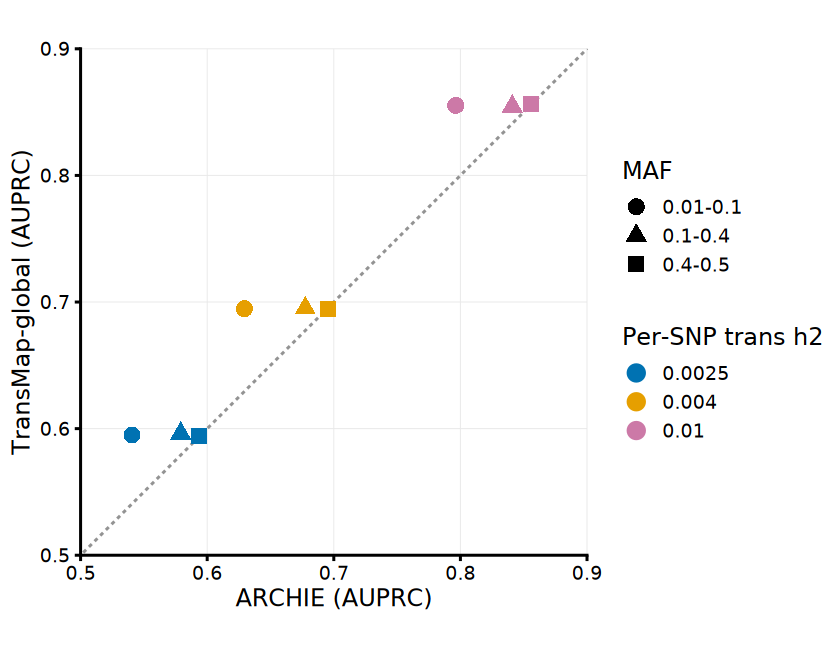

In [2]:
b$h2_label <- factor(b$per_snp_h2, levels = c(0.0025, 0.004, 0.01), labels = c("0.0025", "0.004", "0.01"))
b$maf_band <- factor(b$maf_band, levels = c("0.01-0.1", "0.1-0.4", "0.4-0.5"))
h2_colors <- c("0.0025" = "#0072B2", "0.004" = "#E69F00", "0.01" = "#CC79A7")
lims <- c(0.5, 0.9)

p <- ggplot(b, aes(x = auprc_archie, y = auprc_transmap_global, colour = h2_label, shape = maf_band)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "#939393") +
  geom_point(size = 4, stroke = 0.75) +
  scale_colour_manual(values = h2_colors, name = "Per-SNP trans h2") +
  scale_shape_manual(values = c("0.01-0.1" = 16, "0.1-0.4" = 17, "0.4-0.5" = 15), name = "MAF") +
  coord_fixed(xlim = lims, ylim = lims, expand = FALSE) +
  labs(x = "ARCHIE (AUPRC)", y = "TransMap-global (AUPRC)") +
  theme_classic(base_size = 14) +
  theme(panel.grid.major = element_line(linewidth = 0.2, colour = "#E8E8E8"))

options(repr.plot.width = 7, repr.plot.height = 5.5)
p